# Week 4: Machine Learning Model Development and Evaluation
## Titanic Survival Prediction

**Objective:** Build, train, and evaluate classification models that predict whether a Titanic passenger survived.

This notebook uses a reproducible Scikit-learn pipeline. It compares Logistic Regression and Decision Tree models using the same stratified train/test split and preprocessing steps.

**Dataset:** Titanic passenger dataset (891 rows, 12 columns), loaded from the public CSV URL below.


## 1. Import libraries and load the dataset

The notebook downloads the public Titanic CSV. If the download fails, upload `titanic.csv` to the Colab session and set `DATA_PATH` to its filename.


In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.model_selection import train_test_split
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import OneHotEncoder, StandardScaler
from sklearn.impute import SimpleImputer
from sklearn.linear_model import LogisticRegression
from sklearn.tree import DecisionTreeClassifier
from sklearn.metrics import (
    accuracy_score, precision_score, recall_score, f1_score,
    roc_auc_score, confusion_matrix, ConfusionMatrixDisplay,
    RocCurveDisplay, classification_report
)

DATA_URL = "https://raw.githubusercontent.com/datasciencedojo/datasets/master/titanic.csv"
DATA_PATH = None  # Example: "titanic.csv" if you upload the file manually

if DATA_PATH:
    df = pd.read_csv(DATA_PATH)
else:
    df = pd.read_csv(DATA_URL)

print("Dataset shape:", df.shape)
display(df.head())


Dataset shape: (891, 12)


,PassengerId,Survived,Pclass,Name,Sex,Age,SibSp,Parch,Ticket,Fare,Cabin,Embarked
0,1,0,3,"Braund, Mr. Owen Harris",male,22.0,1,0,A/5 21171,7.2500,NaN,S
1,2,1,1,"Cumings, Mrs. John Bradley (Florence Briggs Th...",female,38.0,1,0,PC 17599,71.2833,C85,C
2,3,1,3,"Heikkinen, Miss. Laina",female,26.0,0,0,STON/O2. 3101282,7.9250,NaN,S
3,4,1,1,"Futrelle, Mrs. Jacques Heath (Lily May Peel)",female,35.0,1,0,113803,53.1000,C123,S
4,5,0,3,"Allen, Mr. William Henry",male,35.0,0,0,373450,8.0500,NaN,S


## 2. Inspect and prepare the data

The target is `Survived` (0 = did not survive, 1 = survived). We retain a small set of interpretable predictors. `Name`, `Ticket`, `Cabin`, and passenger identifiers are excluded from this baseline model.

Missing numeric values are imputed with the median; missing categorical values are imputed with the most frequent category. These transformations are fitted inside each model pipeline using training data only, preventing preprocessing leakage.


In [2]:
print(df.info())
display(df.isna().sum().sort_values(ascending=False))

target = "Survived"
features = ["Pclass", "Sex", "Age", "SibSp", "Parch", "Fare", "Embarked"]

X = df[features].copy()
y = df[target].astype(int)

numeric_features = ["Pclass", "Age", "SibSp", "Parch", "Fare"]
categorical_features = ["Sex", "Embarked"]

numeric_preprocessor = Pipeline(steps=[
    ("imputer", SimpleImputer(strategy="median")),
    ("scaler", StandardScaler())
])

categorical_preprocessor = Pipeline(steps=[
    ("imputer", SimpleImputer(strategy="most_frequent")),
    ("onehot", OneHotEncoder(handle_unknown="ignore"))
])

preprocessor = ColumnTransformer(transformers=[
    ("num", numeric_preprocessor, numeric_features),
    ("cat", categorical_preprocessor, categorical_features)
])


<class 'pandas.core.frame.DataFrame'>
RangeIndex: 891 entries, 0 to 890
Data columns (total 12 columns):
 #   Column       Non-Null Count  Dtype  
---  ------       --------------  -----  
 0   PassengerId  891 non-null    int64  
 1   Survived     891 non-null    int64  
 2   Pclass       891 non-null    int64  
 3   Name         891 non-null    object 
 4   Sex          891 non-null    object 
 5   Age          714 non-null    float64
 6   SibSp        891 non-null    int64  
 7   Parch        891 non-null    int64  
 8   Ticket       891 non-null    object 
 9   Fare         891 non-null    float64
 10  Cabin        204 non-null    object 
 11  Embarked     889 non-null    object 
dtypes: float64(2), int64(5), object(5)
memory usage: 83.7+ KB
None


,0
Cabin,687
Age,177
Embarked,2
PassengerId,0
Name,0
Pclass,0
Survived,0
Sex,0
Parch,0
SibSp,0


## 3. Split the data

A stratified 80/20 split keeps the survival-class proportions approximately consistent in both subsets. The test set is held out for final evaluation.


In [3]:
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.20, random_state=42, stratify=y
)

print("Training rows:", len(X_train))
print("Testing rows:", len(X_test))
print("Training survival rate:", round(y_train.mean(), 3))
print("Testing survival rate:", round(y_test.mean(), 3))


Training rows: 712
Testing rows: 179
Training survival rate: 0.383
Testing survival rate: 0.385


## 4. Select and train models

**Logistic Regression** is a useful baseline for binary classification and offers relatively interpretable coefficients. **Decision Tree** can capture non-linear patterns and interactions, but may overfit if allowed to grow without constraints. A maximum depth is therefore applied as a simple regularization measure.


In [4]:
models = {
    "Logistic Regression": Pipeline(steps=[
        ("preprocessor", preprocessor),
        ("classifier", LogisticRegression(max_iter=1000, random_state=42))
    ]),
    "Decision Tree": Pipeline(steps=[
        ("preprocessor", preprocessor),
        ("classifier", DecisionTreeClassifier(
            max_depth=4, min_samples_leaf=5, random_state=42
        ))
    ])
}

for name, model in models.items():
    model.fit(X_train, y_train)
    print(f"{name}: training complete")


Logistic Regression: training complete
Decision Tree: training complete


## 5. Evaluate model performance

Accuracy measures overall correctness. Precision measures how many predicted survivors actually survived. Recall measures how many actual survivors were identified. F1-score balances precision and recall. ROC-AUC measures ranking ability across classification thresholds.

No single metric should be interpreted alone, especially when class proportions are unequal.


In [5]:
results = []
predictions = {}
probabilities = {}

for name, model in models.items():
    y_pred = model.predict(X_test)
    y_prob = model.predict_proba(X_test)[:, 1]
    predictions[name] = y_pred
    probabilities[name] = y_prob

    results.append({
        "Model": name,
        "Accuracy": accuracy_score(y_test, y_pred),
        "Precision": precision_score(y_test, y_pred, zero_division=0),
        "Recall": recall_score(y_test, y_pred, zero_division=0),
        "F1-score": f1_score(y_test, y_pred, zero_division=0),
        "ROC-AUC": roc_auc_score(y_test, y_prob)
    })

results_df = pd.DataFrame(results).set_index("Model")
display(results_df.round(3))


,Accuracy,Precision,Recall,F1-score,ROC-AUC
Model,,,,,
Logistic Regression,0.804,0.793,0.667,0.724,0.844
Decision Tree,0.777,0.809,0.551,0.655,0.818


## 6. Visualization 1: Compare evaluation metrics

The grouped bar chart compares accuracy, precision, recall, F1-score, and ROC-AUC for both models.


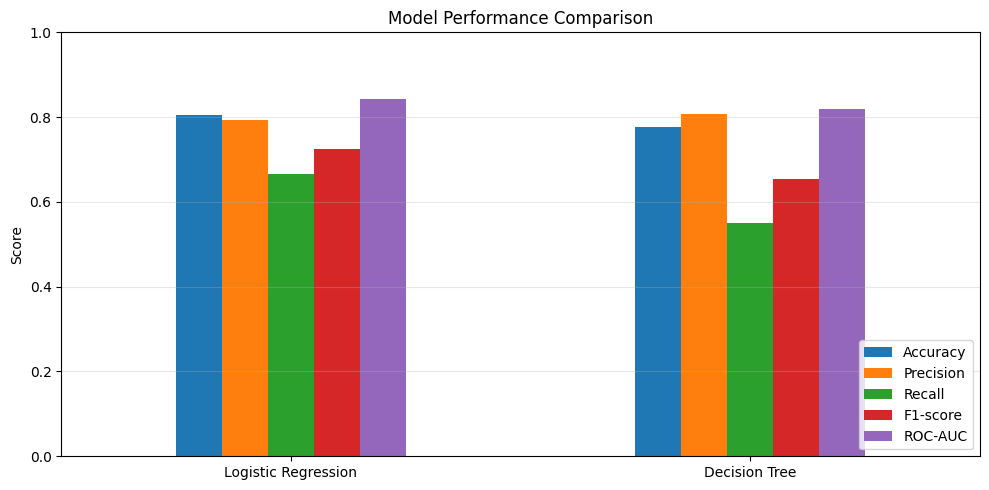

In [6]:
ax = results_df.plot(kind="bar", figsize=(10, 5), ylim=(0, 1), rot=0)
ax.set_title("Model Performance Comparison")
ax.set_ylabel("Score")
ax.set_xlabel("")
ax.legend(loc="lower right")
ax.grid(axis="y", alpha=0.3)
plt.tight_layout()
plt.show()


## 7. Visualization 2: Confusion matrices

A confusion matrix shows true negatives, false positives, false negatives, and true positives. False negatives are actual survivors predicted as non-survivors; false positives are non-survivors predicted as survivors.


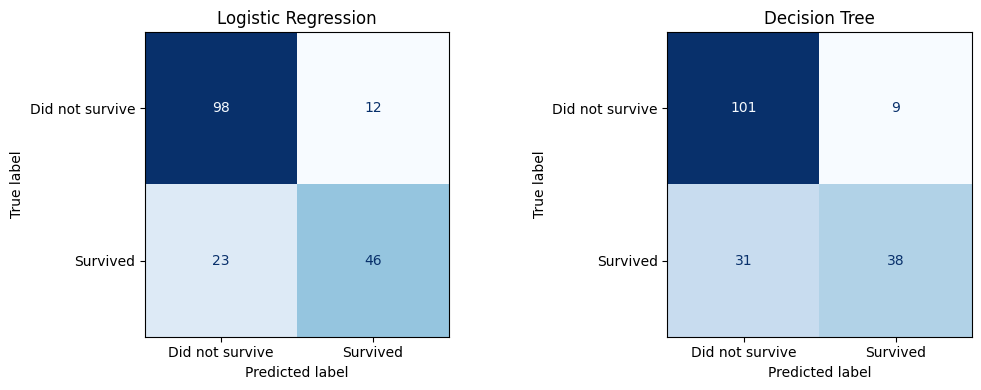

In [7]:
fig, axes = plt.subplots(1, 2, figsize=(11, 4))
for ax, (name, y_pred) in zip(axes, predictions.items()):
    cm = confusion_matrix(y_test, y_pred)
    disp = ConfusionMatrixDisplay(confusion_matrix=cm, display_labels=["Did not survive", "Survived"])
    disp.plot(ax=ax, cmap="Blues", colorbar=False)
    ax.set_title(name)
plt.tight_layout()
plt.show()


## 8. Visualization 3: ROC curves

The ROC curve shows the trade-off between true-positive rate and false-positive rate across thresholds. A curve closer to the top-left generally indicates better discrimination; the diagonal represents chance-level ranking.


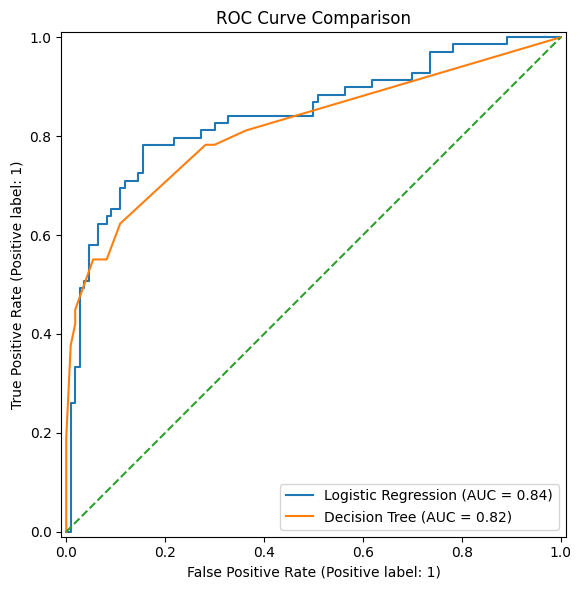

In [8]:
fig, ax = plt.subplots(figsize=(7, 6))
for name, model in models.items():
    RocCurveDisplay.from_estimator(model, X_test, y_test, name=name, ax=ax)
ax.plot([0, 1], [0, 1], linestyle="--", label="Chance")
ax.set_title("ROC Curve Comparison")
plt.tight_layout()
plt.show()


## 9. Detailed classification reports and interpretation

Review the class-wise precision, recall, and F1-score. Compare the training and test scores if you want to investigate overfitting further.


In [9]:
for name, model in models.items():
    print("\\n" + "="*60)
    print(name)
    print(classification_report(y_test, predictions[name], target_names=["Did not survive", "Survived"], zero_division=0))

    train_accuracy = model.score(X_train, y_train)
    test_accuracy = model.score(X_test, y_test)
    print(f"Training accuracy: {train_accuracy:.3f}")
    print(f"Testing accuracy:  {test_accuracy:.3f}")
    print(f"Train-test gap:    {train_accuracy - test_accuracy:.3f}")


\n============================================================
Logistic Regression
                 precision    recall  f1-score   support

Did not survive       0.81      0.89      0.85       110
       Survived       0.79      0.67      0.72        69

       accuracy                           0.80       179
      macro avg       0.80      0.78      0.79       179
   weighted avg       0.80      0.80      0.80       179

Training accuracy: 0.808
Testing accuracy:  0.804
Train-test gap:    0.003
\n============================================================
Decision Tree
                 precision    recall  f1-score   support

Did not survive       0.77      0.92      0.83       110
       Survived       0.81      0.55      0.66        69

       accuracy                           0.78       179
      macro avg       0.79      0.73      0.74       179
   weighted avg       0.78      0.78      0.77       179

Training accuracy: 0.836
Testing accuracy:  0.777
Train-test gap:    0.059


## 10. Critical discussion and possible improvements

### Potential sources of error
- The dataset is historical and may not represent other passenger populations or modern situations.
- Some useful information is missing, especially cabin information and passenger details.
- The selected features do not capture every factor that influenced survival.
- A single train/test split can produce results that vary with the random seed.
- The model learns associations in the dataset; it does not establish causation.

### Overfitting and underfitting
A deep decision tree can memorize training examples and perform less well on unseen data. Limiting tree depth and minimum leaf size reduces this risk. Logistic Regression may underfit if the true relationships are strongly non-linear. Compare training and test performance to identify a large generalization gap.

### Suggested improvements
- Use stratified cross-validation for more stable estimates.
- Tune hyperparameters with GridSearchCV using cross-validation.
- Compare additional models such as Random Forest and Gradient Boosting.
- Examine feature importance and model coefficients carefully.
- Consider threshold tuning based on the relative cost of false positives and false negatives.
- Report confidence intervals or variability across folds.


## 11. Conclusion

This project demonstrates a complete baseline machine-learning workflow: data inspection, preprocessing, stratified splitting, model selection, training, evaluation, and visualization. Logistic Regression and a depth-limited Decision Tree are compared using multiple metrics and diagnostic plots.

**Important:** Run all cells in Google Colab and use the actual metric values printed by the notebook in the Week 4 report. Do not copy placeholder or assumed values.
